# Zadania laboratoryjne nr 1 — rzut ukośny

Grupa:
- Kamil
- Igor Józefowicz 193257

Celem jest wyznaczenie parametrów początkowych, dla których ciało przecina wszystkie wymagane odcinki i omija wszystkie zabronione odcinki.

Przyjmujemy start w (0, 0), brak oporu powietrza oraz g = 10 m/są. Losujemy niezależnie, jednostajnie: α ∈ (1°, 89°), v₀ ∈ (1, 30) m/s.

| Region | Odcinek | Warunek |
|---|---|---|
| R1 | y = 2, x ∈ (4, 10) | musi zostać przecięty |
| R2 | y = 3, x ∈ (7, 8) | nie może zostać przecięty |
| R3 | x = 3, y ∈ (3, 9) | musi zostać przecięty |
| R4 | x = 4, y ∈ (5, 6) | nie może zostać przecięty |

Stosujemy przedziały otwarte zgodnie z powyższym opisem. Współrzędne regionów są danymi przyjętymi w notatniku; instrukcja PDF nie podaje ich wartości liczbowych. Rozwiązanie przygotowano w Pythonie; instrukcja wskazuje Matlab, więc użycie Pythona wymaga akceptacji prowadzącego.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

repetitions = 100_000
seed = 42
rng = np.random.default_rng(seed)
g = 10.0
alpha_min, alpha_max = 1.0, 89.0
v0_min, v0_max = 1.0, 30.0

# Uruchomienie z katalogu repozytorium lub katalogu notatnika.
lab_dir = Path("lab1-body-moving-in-a-uniform-gravitational-field")
output_dir = (lab_dir if lab_dir.is_dir() else Path.cwd()) / "results"
output_dir.mkdir(exist_ok=True)

# (x1, y1, x2, y2); jeden zestaw danych dla obliczeń i wykresu.
regions = {
    "R1": (4.0, 2.0, 10.0, 2.0),
    "R2": (7.0, 3.0, 8.0, 3.0),
    "R3": (3.0, 3.0, 3.0, 9.0),
    "R4": (4.0, 5.0, 4.0, 6.0),
}


## Model i sprawdzanie przecięć

Dla $v_{0x}=v_0\cos\alpha$ i $v_{0y}=v_0\sin\alpha$:

$$x(t)=v_{0x}t,\qquad y(t)=v_{0y}t-\frac12gt^2.$$

Lot trwa od $t=0$ do $T=2v_{0y}/g$. Dla odcinka pionowego podstawiamy $t=x/v_{0x}$. Dla odcinka poziomego rozwiązujemy równanie $-gt^2/2+v_{0y}t-h=0$ i sprawdzamy **oba** pierwiastki, o ile wyróżnik jest nieujemny. Uwzględniamy wyłącznie punkty podczas lotu i wnętrze odcinka. Dzięki temu wynik nie zależy od kroku próbkowania trajektorii do wykresu.


In [2]:
def crosses_region(v0x, v0y, region):
    """Maska przecięcia otwartego odcinka podczas lotu; obsługuje tablice."""
    x1, y1, x2, y2 = region
    flight_time = 2 * v0y / g
    if x1 == x2:
        t = x1 / v0x
        height = v0y * t - 0.5 * g * t**2
        return ((t >= 0) & (t <= flight_time)
                & (height > min(y1, y2)) & (height < max(y1, y2)))
    if y1 == y2:
        delta = v0y**2 - 2 * g * y1
        root = np.sqrt(np.maximum(delta, 0))
        t1 = (v0y - root) / g
        t2 = (v0y + root) / g
        def on_segment(t):
            x = v0x * t
            return ((t >= 0) & (t <= flight_time)
                    & (x > min(x1, x2)) & (x < max(x1, x2)))
        return (delta >= 0) & (on_segment(t1) | on_segment(t2))
    raise ValueError("Obsługiwane są odcinki poziome i pionowe.")


def evaluate_trajectories(v0, alpha):
    v0x = v0 * np.cos(np.deg2rad(alpha))
    v0y = v0 * np.sin(np.deg2rad(alpha))
    crossed = {name: crosses_region(v0x, v0y, region)
               for name, region in regions.items()}
    accepted = crossed["R1"] & ~crossed["R2"] & crossed["R3"] & ~crossed["R4"]
    return accepted, crossed


## Zadanie 2.1 — 100 000 losowań i dopuszczalne parametry

Stałe ziarno generatora umożliwia odtworzenie wyników. Każda para jest osobną próbą; sprawdzamy przecięcia analitycznie, korzystając z równań ruchu.


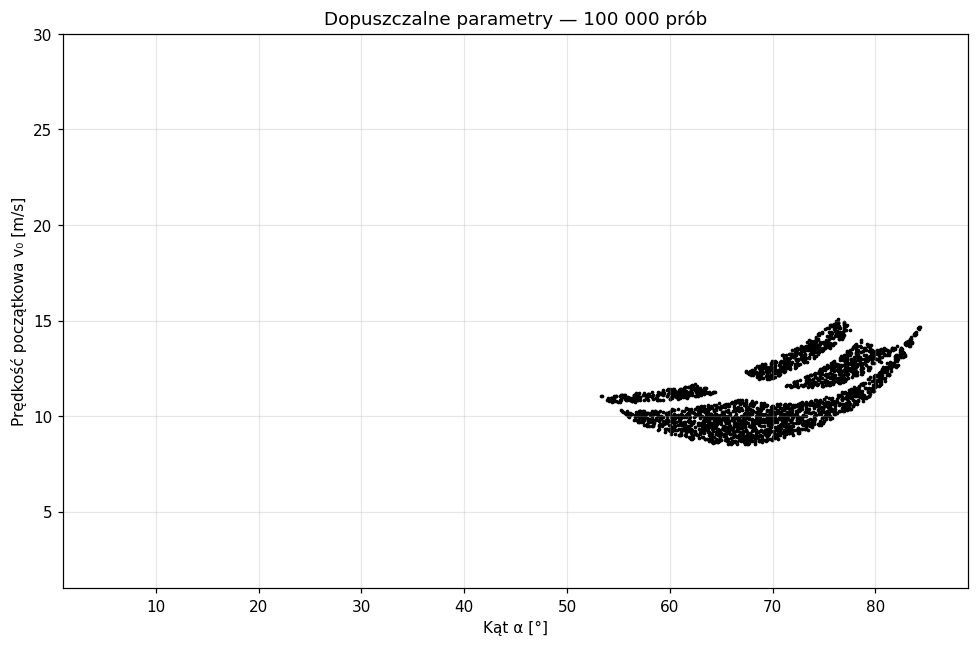

Zaakceptowano 2616 z 100000 prób.


In [3]:
alpha = rng.uniform(alpha_min, alpha_max, repetitions)
v0 = rng.uniform(v0_min, v0_max, repetitions)
accepted, crossed = evaluate_trajectories(v0, alpha)
accepted_trajectories_count = int(np.count_nonzero(accepted))
accepted_alpha = alpha[accepted]
accepted_v0 = v0[accepted]
print(f"Zaakceptowano {accepted_trajectories_count} z {repetitions} prób.")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(accepted_alpha, accepted_v0, s=2, color="black")
ax.set(xlabel="Kąt α [°]", ylabel="Prędkość początkowa v₀ [m/s]",
       xlim=(alpha_min, alpha_max), ylim=(v0_min, v0_max),
       title=f"Dopuszczalne parametry — {repetitions:,} prób".replace(",", " "))
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / "allowed_parameters.png", dpi=180)
plt.show()


## Zadanie 2.2 — regiony i pięć poprawnych trajektorii

Wybieramy pięć par z zaakceptowanego zbioru, rozłożonych według kąta. Zielone odcinki muszą zostać przecięte, czerwone muszą zostać ominięte. Każdą trajektorię rysujemy od startu do powrotu na poziom y = 0.


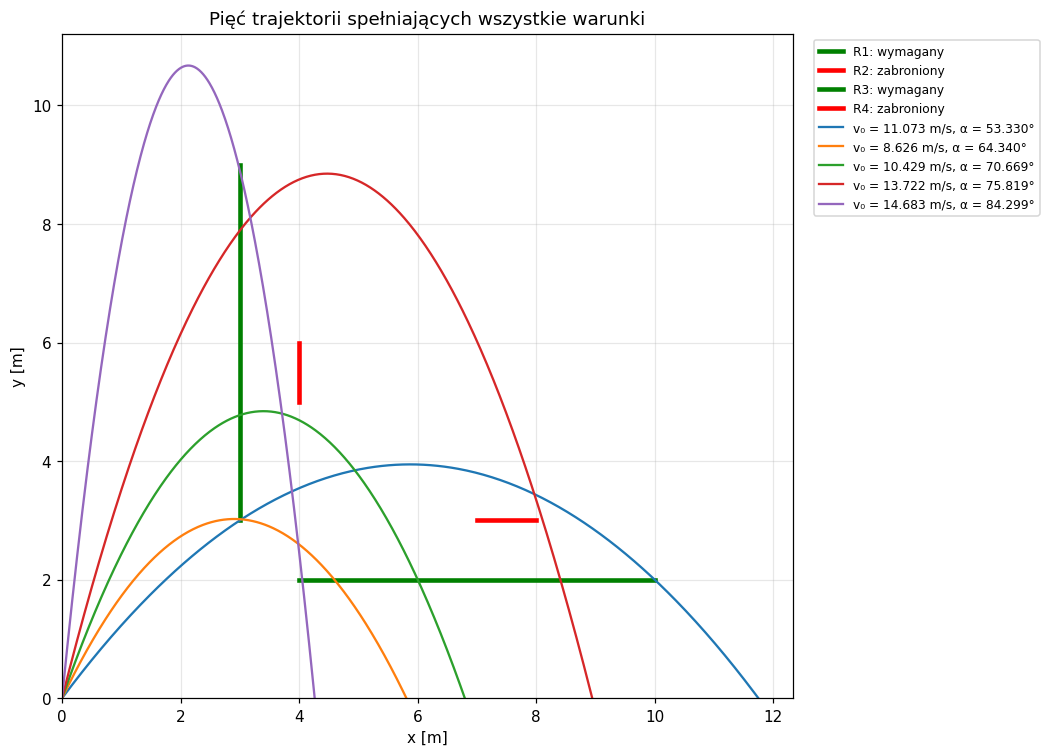

Parametry przykładów (obliczenia korzystają z pełnej precyzji):
v₀ = 11.07348415 m/s, α = 53.32956592°
v₀ = 8.62647142 m/s, α = 64.34032657°
v₀ = 10.42889628 m/s, α = 70.66855678°
v₀ = 13.72199752 m/s, α = 75.81921653°
v₀ = 14.68308832 m/s, α = 84.29908400°


In [4]:
if accepted_trajectories_count < 5:
    raise RuntimeError("Mniej niż pięć poprawnych par — nie można wykonać wykresu.")
order = np.argsort(accepted_alpha)
selected = order[np.linspace(0, len(order) - 1, 5, dtype=int)]
example_v0 = accepted_v0[selected]
example_alpha = accepted_alpha[selected]

fig, ax = plt.subplots(figsize=(11, 7))
for name, (x1, y1, x2, y2) in regions.items():
    required = name in ("R1", "R3")
    ax.plot([x1, x2], [y1, y2], color="green" if required else "red",
            linewidth=3, label=f"{name}: {'wymagany' if required else 'zabroniony'}")

for speed, angle in zip(example_v0, example_alpha):
    vx = speed * np.cos(np.deg2rad(angle))
    vy = speed * np.sin(np.deg2rad(angle))
    t = np.linspace(0, 2 * vy / g, 500)
    ax.plot(vx * t, vy * t - 0.5 * g * t**2,
            label=f"v₀ = {speed:.3f} m/s, α = {angle:.3f}°")

ax.set(xlabel="x [m]", ylabel="y [m]", title="Pięć trajektorii spełniających wszystkie warunki")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.3)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
fig.tight_layout()
fig.savefig(output_dir / "accepted_trajectories.png", dpi=180)
plt.show()

print("Parametry przykładów (obliczenia korzystają z pełnej precyzji):")
for speed, angle in zip(example_v0, example_alpha):
    print(f"v₀ = {speed:.8f} m/s, α = {angle:.8f}°")


## Zadanie 2.3 — prawdopodobieństwo i dokładność

Estymator Monte Carlo to $\hat p=k/N$, gdzie $k$ oznacza liczbę zaakceptowanych prób, a $N$ liczbę wszystkich prób. Wynik dotyczy **niezależnego, jednostajnego** losowania kąta i prędkości z zadanych przedziałów; inny rozkład losowania może dać inne prawdopodobieństwo.

Dla niezależnych prób błąd standardowy szacujemy jako:

$$SE(\hat p)\approx\sqrt{\frac{\hat p(1-\hat p)}{N}}.$$

Przy dużej liczbie sukcesów i porażek przybliżony przedział ufności 95% ma postać $\hat p\pm1{,}96\,SE$. Opisuje niepewność losowania, a nie błędy modelu lub implementacji.

Dokładność zależy od liczby prób, prawdopodobieństwa zdarzenia, niezależności i jakości losowania oraz poprawności sprawdzania warunków. Błąd maleje jak $1/\sqrt{N}$: aby zmniejszyć go dwukrotnie, trzeba wykonać około czterokrotnie więcej prób. Stałe ziarno zapewnia powtarzalność, ale nie zwiększa dokładności.


In [5]:
probability = accepted_trajectories_count / repetitions
standard_error = np.sqrt(probability * (1 - probability) / repetitions)
margin = 1.96 * standard_error
ci_low = max(0.0, probability - margin)
ci_high = min(1.0, probability + margin)

summary = (
    f"Liczba prób: {repetitions}\n"
    f"Liczba zaakceptowanych: {accepted_trajectories_count}\n"
    f"Ziarno generatora: {seed}\n"
    f"Prawdopodobieństwo: {probability:.6f} = {100 * probability:.4f}%\n"
    f"Błąd standardowy: {100 * standard_error:.4f} punktu procentowego\n"
    f"Przybliżony przedział ufności 95%: [{100 * ci_low:.4f}%, {100 * ci_high:.4f}%]\n"
    f"Margines 95%: ±{100 * margin:.4f} punktu procentowego\n"
)
print(summary)
(output_dir / "probability_summary.txt").write_text(summary, encoding="utf-8")
print(f"Wykresy i podsumowanie zapisano w: {output_dir.resolve()}")


Liczba prób: 100000
Liczba zaakceptowanych: 2616
Ziarno generatora: 42
Prawdopodobieństwo: 0.026160 = 2.6160%
Błąd standardowy: 0.0505 punktu procentowego
Przybliżony przedział ufności 95%: [2.5171%, 2.7149%]
Margines 95%: ±0.0989 punktu procentowego

Wykresy i podsumowanie zapisano w: C:\Users\igor\source\systems-modeling-and-simulation\lab1-body-moving-in-a-uniform-gravitational-field\results


## Materiały do sprawozdania

Kod i wyniki znajdują się w tym notatniku. Po wykonaniu wszystkich komórek katalog `results` zawiera:
- `allowed_parameters.png` — dopuszczalne pary parametrów;
- `accepted_trajectories.png` — regiony i pięć poprawnych trajektorii;
- `probability_summary.txt` — oszacowanie prawdopodobieństwa i jego niepewności.

Instrukcja wymaga pokazania obu wykresów prowadzącemu do akceptacji oraz przesłania kodu, opisanych wykresów i odpowiedzi do zadania 2.3. Tytuł wiadomości powinien wskazywać grupę studencką.
